# Training and Test Errors, Cross-Validation, Pipelines

In [26]:
import pandas as pd
import numpy as np

from plotnine import *

**Use scikit-learn, including pipelines, whenever possible.**

## Ames Housing Data


We have fit different regression models to predict house prices (SalePrice, not log). Now we will evaluate models by estimating their prediction error.

In [27]:
df_ames = pd.read_csv("http://dlsun.github.io/pods/data/AmesHousing.txt", sep = "\t")

df_ames

,Order,PID,MS SubClass,MS Zoning,Lot Frontage,Lot Area,Street,Alley,Lot Shape,Land Contour,...,Pool Area,Pool QC,Fence,Misc Feature,Misc Val,Mo Sold,Yr Sold,Sale Type,Sale Condition,SalePrice
0,1,526301100,20,RL,141.0,31770,Pave,NaN,IR1,Lvl,...,0,NaN,NaN,NaN,0,5,2010,WD,Normal,215000
1,2,526350040,20,RH,80.0,11622,Pave,NaN,Reg,Lvl,...,0,NaN,MnPrv,NaN,0,6,2010,WD,Normal,105000
2,3,526351010,20,RL,81.0,14267,Pave,NaN,IR1,Lvl,...,0,NaN,NaN,Gar2,12500,6,2010,WD,Normal,172000
3,4,526353030,20,RL,93.0,11160,Pave,NaN,Reg,Lvl,...,0,NaN,NaN,NaN,0,4,2010,WD,Normal,244000
4,5,527105010,60,RL,74.0,13830,Pave,NaN,IR1,Lvl,...,0,NaN,MnPrv,NaN,0,3,2010,WD,Normal,189900
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2925,2926,923275080,80,RL,37.0,7937,Pave,NaN,IR1,Lvl,...,0,NaN,GdPrv,NaN,0,3,2006,WD,Normal,142500
2926,2927,923276100,20,RL,NaN,8885,Pave,NaN,IR1,Low,...,0,NaN,MnPrv,NaN,0,6,2006,WD,Normal,131000
2927,2928,923400125,85,RL,62.0,10441,Pave,NaN,Reg,Lvl,...,0,NaN,MnPrv,Shed,700,7,2006,WD,Normal,132000
2928,2929,924100070,20,RL,77.0,10010,Pave,NaN,Reg,Lvl,...,0,NaN,NaN,NaN,0,4,2006,WD,Normal,170000


Since all of the houses in the data set have a SalePrice, we'll include all the observations in the training data. We'll start with a basic linear regression model with a few features.

In [28]:
X_train = df_ames[["Gr Liv Area", "Bedroom AbvGr", "Full Bath", "Half Bath"]]

y_train = df_ames["SalePrice"]

In [29]:
from sklearn.linear_model import LinearRegression

model1 = LinearRegression()
model1.fit(
    X=X_train,
    y=y_train
)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


1. Explain conceptually what the "fit" step does. What is the output?

**Answer (Q1):** The "fit" step is where the model **learns from the training data**. For linear regression, `fit` finds the intercept and the coefficients (one slope per feature) that make the **sum of squared residuals as small as possible** on the training houses (least squares). The output is the **fitted model object**, which now stores the learned numbers (`model1.intercept_` and `model1.coef_`) and can be used to `.predict()` the price of any house.

In [30]:
# Look at what "fit" learned: one intercept and one coefficient for each feature
print("Intercept:", round(model1.intercept_, 2))
pd.Series(model1.coef_, index=X_train.columns)

Intercept: 46942.32


Gr Liv Area        118.099868
Bedroom AbvGr   -29994.956760
Full Bath        26728.533428
Half Bath         1271.138477
dtype: float64

2. Explain conceptually how you would compute the *training* RMSE (root mean square error) of this model.

**Answer (Q2):** To compute the *training* RMSE:

1. Use the fitted model to predict the price of **every house in the training data**: `y_hat = model1.predict(X_train)`.
2. Find each house's error (residual): `y - y_hat` (actual minus predicted).
3. **Square** each error, take the **mean** (that is the MSE), then take the **square root** (that is the RMSE).

The RMSE is a "typical" size of the prediction error, in the same units as the target (dollars).

In [31]:
from sklearn.metrics import mean_squared_error

# 1. predictions on the training data
y_hat_train = model1.predict(X_train)

# 2-3. squared errors -> mean -> square root
train_rmse = np.sqrt(mean_squared_error(y_train, y_hat_train))
print(f"Training RMSE of model1: ${train_rmse:,.0f}")

Training RMSE of model1: $51,350


3. Interpret the *training RMSE*. Is it big or small? What could you use as a rough benchmark for comparison?

**Answer (Q3):** The training RMSE says that the model's predictions are off by roughly that many dollars for a typical house. Whether that is big or small depends on the scale of the prices, so we need a **benchmark**. A good rough benchmark is the **standard deviation of SalePrice**: that is the RMSE we would get if we ignored all the features and predicted the average price for every house. The model is useful only if its RMSE is clearly *smaller* than that. We can also compare the RMSE to the typical house price (mean or median) to see the error in percentage terms.

In [32]:
# Benchmarks for judging the RMSE
print(f"Training RMSE of model1       : ${train_rmse:,.0f}")
print(f"Std. dev. of SalePrice        : ${y_train.std():,.0f}   (RMSE of always predicting the mean)")
print(f"Median SalePrice              : ${y_train.median():,.0f}")
print(f"RMSE as % of median price     : {100 * train_rmse / y_train.median():.0f}%")
print(f"RMSE as % of the std. dev.    : {100 * train_rmse / y_train.std():.0f}%")

Training RMSE of model1       : $51,350
Std. dev. of SalePrice        : $79,887   (RMSE of always predicting the mean)
Median SalePrice              : $160,000
RMSE as % of median price     : 32%
RMSE as % of the std. dev.    : 64%


4. Suppose we add more features like "TotRms AbvGrd" and fit a new model. Would the *training* RMSE increase or decrease? Why is comparing the *training* RMSE of these two models not useful?

**Answer (Q4):** The training RMSE will **decrease** (or at worst stay the same). Least squares can always give the new feature a coefficient of 0, which recovers the old model, so adding a feature can never make the fit to the training data worse. In practice it almost always goes down a little, even if the new feature is just noise.

That is why comparing the *training* RMSE of the two models is **not useful**: the bigger model *always* wins on training data, whether or not the extra feature really helps predict **new** houses. The training RMSE rewards complexity and overfitting. We need an error computed on data the model did not train on (the test error).

In [33]:
# Demonstration: the training RMSE can only go down when we add a feature
extra_cols = ["Gr Liv Area", "Bedroom AbvGr", "Full Bath", "Half Bath", "TotRms AbvGrd"]
model_more = LinearRegression().fit(df_ames[extra_cols], df_ames["SalePrice"])

rmse_more = np.sqrt(mean_squared_error(df_ames["SalePrice"], model_more.predict(df_ames[extra_cols])))
print(f"Training RMSE, 4 features: ${train_rmse:,.0f}")
print(f"Training RMSE, 5 features: ${rmse_more:,.0f}")

Training RMSE, 4 features: $51,350
Training RMSE, 5 features: $51,350


5. If we fit a 1-nearest neighbor model, what should the *training* RMSE be?

**Answer (Q5):** The training RMSE should be **0** (or essentially 0). When we predict a house that is in the training data, its nearest neighbor is **itself**, so the prediction is exactly its own price and the error is zero. (The only exception: two different houses with identical feature values but different prices. Then each one's nearest neighbors tie, and the error is not exactly 0.) A training RMSE of 0 does not mean the model is good; it means the model memorized the training data.

In [34]:
from sklearn.neighbors import KNeighborsRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

# 1-nearest neighbors on the same 4 features (scaled, because KNN uses distances)
knn1 = make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=1))
knn1.fit(df_ames[["Gr Liv Area", "Bedroom AbvGr", "Full Bath", "Half Bath"]], df_ames["SalePrice"])

pred = knn1.predict(df_ames[["Gr Liv Area", "Bedroom AbvGr", "Full Bath", "Half Bath"]])
print(f"Training RMSE of 1-NN: ${np.sqrt(mean_squared_error(df_ames['SalePrice'], pred)):,.0f}")

Training RMSE of 1-NN: $21,929


6. What happens to the *training* RMSE of a $k$-nearest neighbors model as $k$ increases?

**Answer (Q6):** As $k$ increases, the *training* RMSE generally **increases**. With $k = 1$ the model memorizes the training data (RMSE of about 0). As $k$ grows, each prediction averages more houses, so the model gets smoother and less flexible and fits the training data less closely. At the extreme $k = n$, every prediction is the overall mean, and the RMSE equals the standard deviation of the prices. So a small training RMSE is *not* a sign of a good model: the training error always favors the smallest $k$.

In [35]:
# Training RMSE of k-nearest neighbors for several values of k
feat4 = ["Gr Liv Area", "Bedroom AbvGr", "Full Bath", "Half Bath"]
rows = []
for k in [1, 2, 5, 10, 25, 50, 100, 500, len(df_ames)]:
    knn = make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=k))
    knn.fit(df_ames[feat4], df_ames["SalePrice"])
    rmse_k = np.sqrt(mean_squared_error(df_ames["SalePrice"], knn.predict(df_ames[feat4])))
    rows.append({"k": k, "training RMSE": round(rmse_k)})
pd.DataFrame(rows).set_index("k")

,training RMSE
k,
1,21929
2,30689
5,39542
10,42198
25,44421
50,46542
100,48983
500,59366
2930,79873


7. We are really interested in the *test* RMSE, not the *training* RMSE. Explain why in practice you can not compute the *test* RMSE.

**Answer (Q7):** The *test* data is **new data** (for example, houses that have not sold yet, or that we have not seen), so we **do not know their true prices**. To compute an RMSE we need to compare predictions to the true values, and for the test data those true values are unknown. We can only compute the training error, because that is the only data where we know the true prices, and the training error is too optimistic. This is why we need a way to *estimate* the test error from the training data (validation sets and cross-validation).

8. Explain conceptually how cross-validations *estimates* the *test* RMSE.

**Answer (Q8):** Cross-validation **pretends part of the training data is new data**:

1. Randomly split the training data into $K$ equal-sized groups (**folds**), e.g. $K = 10$.
2. Hold out fold 1 as a "validation set". **Fit the model** on the other $K - 1$ folds.
3. Use that model to **predict the held-out fold** and calculate the RMSE (the model never saw those houses or their prices).
4. Repeat so that **every fold takes a turn** as the validation set.
5. **Average** the $K$ RMSEs. This average is the cross-validation **estimate of the test RMSE**.

Every house is used for validation exactly once, and each time it is predicted by a model that did not train on it. So the estimate behaves like a test error, but it only uses the data we already have.

9. We'll use cross-validation to estimate the *test* RMSE for the model from part 1. Will the *test* RMSE be greater than, less than, or equal to the *training* RMSE for this model?

**Answer (Q9):** The *test* RMSE will be **greater than** the training RMSE (in general). It is harder to predict houses the model has not seen than houses it was fit to. For a simple linear regression with only 4 features there is little overfitting, so the two numbers should be **fairly close**, but the CV estimate will still be a bit higher. (CV estimates are noisy, so a very small difference could go either way.)

In [36]:
from sklearn.model_selection import cross_val_score, KFold

# Use the SAME shuffled 10 folds for every model, so comparisons are fair.
cv = KFold(n_splits=10, shuffle=True, random_state=5544)

X_four = df_ames[["Gr Liv Area", "Bedroom AbvGr", "Full Bath", "Half Bath"]]
y_all = df_ames["SalePrice"]

# cross_val_score returns NEGATIVE mean squared errors (scikit-learn wants scores that are maximized).
scores = cross_val_score(LinearRegression(), X_four, y_all, scoring="neg_mean_squared_error", cv=cv)
cv_rmse_model1 = np.sqrt(-scores).mean()          # negate, square root, then average over the folds

print(f"Training RMSE      : ${train_rmse:,.0f}")
print(f"CV (test) RMSE est.: ${cv_rmse_model1:,.0f}")

Training RMSE      : $51,350
CV (test) RMSE est.: $51,354


10. Suppose we add features like we did in part 4. Will the *test* RMSE necessarily decrease? Fit the test RMSE and compare the two models - which is better based on this criteria?

**Answer (Q10):** **No**, the test RMSE does not necessarily decrease. A feature that carries real information about price lowers it, but a feature that is mostly noise (or just repeats information already in the model) can leave it unchanged or make it a bit **worse**, because the model fits noise in each training fold. "TotRms AbvGrd" overlaps heavily with Gr Liv Area and Bedroom AbvGr, so we should not expect a big improvement. The code compares the cross-validated RMSEs. **The better model is the one with the smaller CV RMSE** (compare the two numbers printed below).

In [37]:
# Compare model 1 (4 features) with a model that also has TotRms AbvGrd, using cross-validation
feat5 = ["Gr Liv Area", "Bedroom AbvGr", "Full Bath", "Half Bath", "TotRms AbvGrd"]

scores5 = cross_val_score(LinearRegression(), df_ames[feat5], y_all, scoring="neg_mean_squared_error", cv=cv)
cv_rmse_5 = np.sqrt(-scores5).mean()

print(f"CV RMSE, 4 features (model1)       : ${cv_rmse_model1:,.0f}")
print(f"CV RMSE, + TotRms AbvGrd           : ${cv_rmse_5:,.0f}")
print("Better model by CV RMSE:", "with TotRms AbvGrd" if cv_rmse_5 < cv_rmse_model1 else "model1 (4 features)")

CV RMSE, 4 features (model1)       : $51,354
CV RMSE, + TotRms AbvGrd           : $51,374
Better model by CV RMSE: model1 (4 features)


11. Now suppose we add a categorical predictor like Neighborhood. The crossval code below will (probably) error. Explain why. Hint: think about how the cross-validation process works and how categorical variables are treated.

In [38]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsRegressor

ct = ColumnTransformer(
    [("standardize", StandardScaler(), ["Gr Liv Area", "Bedroom AbvGr", "Full Bath", "Half Bath"],),
     ("dummify", OneHotEncoder(), ["Neighborhood"]),
    ],
    remainder="drop",
)

neighborhood_model = Pipeline(
    [("preprocessing", ct),
     ("lm", LinearRegression())]
)

X_train = df_ames[["Gr Liv Area", "Bedroom AbvGr", "Full Bath", "Half Bath", "Neighborhood"]]
y_train = df_ames["SalePrice"]

neighborhood_model.fit(X_train, y_train)

,steps,"[('preprocessing', ...), ('lm', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('standardize', ...), ('dummify', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [39]:
from sklearn.model_selection import cross_val_score

# The original code. Some folds fail, so scikit-learn prints warnings ("Found unknown categories ...")
# and returns nan for those folds. (We wrap it in try/except in case it raises an error instead.)
try:
    scores = cross_val_score(neighborhood_model,
                             X = X_train,
                             y = y_train,
                             scoring="neg_mean_squared_error",
                             cv=10)
    print(scores)
except Exception as e:
    print("ERROR:", type(e).__name__)
    print(str(e)[:400])

C:\Users\sammy\anaconda3\Lib\site-packages\sklearn\model_selection\_validation.py:971: UserWarning: Scoring failed. The score on this train-test partition for these parameters will be set to nan. Details: 
Traceback (most recent call last):
  File "C:\Users\sammy\anaconda3\Lib\site-packages\sklearn\metrics\_scorer.py", line 152, in __call__
    score = scorer._score(
        cached_call, estimator, *args, **routed_params.get(name).score
    )
  File "C:\Users\sammy\anaconda3\Lib\site-packages\sklearn\metrics\_scorer.py", line 400, in _score
    y_pred = method_caller(
        estimator,
    ...<2 lines>...
        pos_label=pos_label,
    )
  File "C:\Users\sammy\anaconda3\Lib\site-packages\sklearn\metrics\_scorer.py", line 90, in _cached_call
    result, _ = _get_response_values(
                ~~~~~~~~~~~~~~~~~~~~^
        estimator, *args, response_method=response_method, **kwargs
        ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
    )
    ^
  File "C:\Users\sammy

[-1.44545805e+09 -2.17595113e+09 -1.03959073e+09 -1.75337718e+09
 -1.09461208e+09 -2.46144632e+09 -1.41980610e+09 -2.32075609e+09
 -1.21633483e+09             nan]


**Answer (Q11, categorical predictor error):** Look at the output of the cell above: instead of 10 scores, some are `nan` and there are warnings saying `Found unknown categories ... during transform` (depending on the scikit-learn version it can also stop with an error). `neighborhood_model.fit(X_train, y_train)` worked because the `OneHotEncoder` saw **all** the neighborhoods. In cross-validation the whole pipeline (including the encoder) is **re-fit on each training fold**, and the encoder only learns the categories that appear in *that training fold*. Some neighborhoods are rare (a few have only 1 to 8 houses). When all of a rare neighborhood's houses fall in the **validation fold**, the encoder fit on the training folds has **never seen that category**. The validation fold then contains an "unknown category" and the encoder fails on that fold, which is why we get the warning and the `nan` score. (With `cv=10` and no shuffling the folds are consecutive blocks of rows, and the data is roughly ordered by neighborhood, which makes this even more likely.)

**Fix:** tell the encoder what to do with a category it did not see in training: `OneHotEncoder(handle_unknown="ignore")`. Unknown neighborhoods are then encoded as all zeros (no neighborhood effect), and the predictions go on.

In [40]:
# The fix: handle_unknown="ignore"
ct_fixed = ColumnTransformer(
    [("standardize", StandardScaler(), ["Gr Liv Area", "Bedroom AbvGr", "Full Bath", "Half Bath"]),
     ("dummify", OneHotEncoder(handle_unknown="ignore"), ["Neighborhood"])],
    remainder="drop",
)
neighborhood_model_fixed = Pipeline([("preprocessing", ct_fixed), ("lm", LinearRegression())])

scores = cross_val_score(neighborhood_model_fixed, X_train, y_train,
                         scoring="neg_mean_squared_error", cv=cv)
print(f"CV RMSE with Neighborhood: ${np.sqrt(-scores).mean():,.0f}")

CV RMSE with Neighborhood: $39,567


11. Going back to part 1, suppose we had standardized the features first. Would the coeffiecients of the fitted model change? Would the *training* RMSE change?

**Answer (Q11, standardizing):** The **coefficients would change**. Standardizing rewrites each feature in "standard deviations from its mean" instead of its original units (square feet, bedrooms, ...). Each new coefficient equals the old coefficient times that feature's standard deviation, and it now means "change in price for a one-standard-deviation increase". The intercept also changes (it becomes the predicted price for a house with average values of all features).

The **training RMSE would not change**. Standardizing only rescales and shifts each feature, so the set of predictions a linear model can produce is exactly the same, and least squares finds the same fitted values and residuals. (Standardizing matters for KNN, which uses distances, and for penalized regression, but not for the fit of ordinary linear regression.)

In [41]:
# Check: same training RMSE, different coefficients
feat4 = ["Gr Liv Area", "Bedroom AbvGr", "Full Bath", "Half Bath"]
std_model = make_pipeline(StandardScaler(), LinearRegression()).fit(df_ames[feat4], df_ames["SalePrice"])

rmse_std = np.sqrt(mean_squared_error(df_ames["SalePrice"], std_model.predict(df_ames[feat4])))
print(f"Training RMSE, original features    : ${train_rmse:,.2f}")
print(f"Training RMSE, standardized features: ${rmse_std:,.2f}")

pd.DataFrame({
    "original coef": model1.coef_,
    "standardized coef": std_model[-1].coef_,
}, index=feat4).round(2)

Training RMSE, original features    : $51,350.42
Training RMSE, standardized features: $51,350.42


,original coef,standardized coef
Gr Liv Area,118.10,59690.34
Bedroom AbvGr,-29994.96,-24823.52
Full Bath,26728.53,14776.77
Half Bath,1271.14,638.80


12. Suppose we want to standardize predictors like in the previous part and estimate test RMSE using cross-validation. Explain how standardization fits in in the CV process. Also explain why it is important to put standardization as part of the model pipeline.

**Answer (Q12):** In cross-validation, for **each fold** the standardization must be done like this: compute the mean and standard deviation of each feature using **only the training folds**, standardize the training folds with those numbers, fit the model, then standardize the **validation fold with the same training means and standard deviations** and predict.

It is important to put standardization **inside the pipeline** because `cross_val_score` re-fits the *whole* pipeline on each training fold, so the scaler automatically learns its numbers from the right data every time. If instead we standardize the full data set *before* cross-validation, the means and standard deviations are computed using the validation houses too. That is **data leakage**: information from the validation data sneaks into training, and the CV estimate becomes slightly too optimistic. It also repeats the mistake in the textbook's cautionary tale: new data must go through *exactly* the same preprocessing (with the training numbers) as the training data.

In [42]:
# Wrong way: standardize ALL of the data first, then cross-validate (leaks information from the validation folds)
X_leaky = (X_four - X_four.mean()) / X_four.std()
leaky = np.sqrt(-cross_val_score(LinearRegression(), X_leaky, y_all,
                                 scoring="neg_mean_squared_error", cv=cv)).mean()

# Right way: StandardScaler is a step of the pipeline, re-fit on the training folds of each split
pipe_std = make_pipeline(StandardScaler(), LinearRegression())
proper = np.sqrt(-cross_val_score(pipe_std, X_four, y_all,
                                  scoring="neg_mean_squared_error", cv=cv)).mean()

print(f"CV RMSE, standardize before CV (leaky): ${leaky:,.2f}")
print(f"CV RMSE, scaler inside pipeline        : ${proper:,.2f}")
# For linear regression the two are almost identical, but the pipeline is the correct habit
# (and it matters more for KNN and other models).

CV RMSE, standardize before CV (leaky): $51,354.33
CV RMSE, scaler inside pipeline        : $51,354.33


## Practice Activity

We'll continue with the housing data and our goal of predicting Sale Price.

We will have a competition to see who can come up with the model with the smallest *test* RMSE. Fit several models and try to find the smallest *test* RMSE. Use cross-validation to estimate the *test* RMSE. When you think you have a good model, share your it and its test RMSE with a partner. Then see what other people have done; can you do even better?

Note: next week we will see how to make some of these choices in a more automated way. For now just work by trial and error. You should try:

- Exploring the data first! Make some plots and summaries to get an idea of what might be good predictors to try
- Several different sets of predictors, including both categorical and numerical predictors
- Linear regression models, including models with polynomial features and interactions
- K-nearest neighbors models, inclduing different values of k
- Decision trees, including different sizes of trees

Use pipelines as much as possible, and don't forget to transform variables as needed.

### Step 1: Explore the data first

In [43]:
import matplotlib.pyplot as plt

# Which numeric columns are most strongly related to SalePrice?
corr = df_ames.corr(numeric_only=True)["SalePrice"].drop("SalePrice")
corr.reindex(corr.abs().sort_values(ascending=False).index).head(12).round(2)

Overall Qual      0.80
Gr Liv Area       0.71
Garage Cars       0.65
Garage Area       0.64
Total Bsmt SF     0.63
1st Flr SF        0.62
Year Built        0.56
Full Bath         0.55
Year Remod/Add    0.53
Garage Yr Blt     0.53
Mas Vnr Area      0.51
TotRms AbvGrd     0.50
Name: SalePrice, dtype: float64

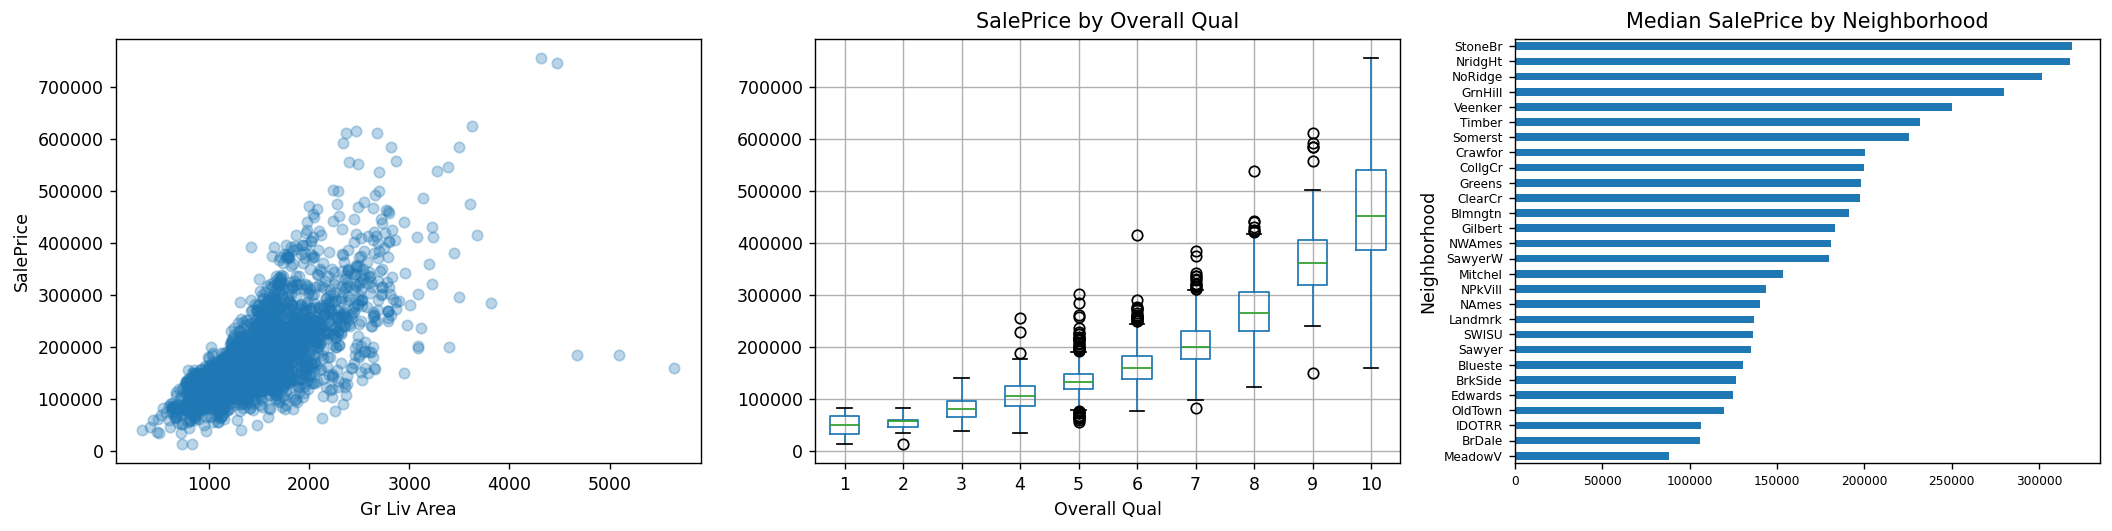

In [44]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

# Size vs price (numeric)
axes[0].scatter(df_ames["Gr Liv Area"], df_ames["SalePrice"], alpha=0.3)
axes[0].set_xlabel("Gr Liv Area"); axes[0].set_ylabel("SalePrice")

# Overall quality vs price (a 1-10 rating)
df_ames.boxplot(column="SalePrice", by="Overall Qual", ax=axes[1])
axes[1].set_title("SalePrice by Overall Qual"); axes[1].set_xlabel("Overall Qual")

# Neighborhood vs price (median price, sorted)
df_ames.groupby("Neighborhood")["SalePrice"].median().sort_values().plot.barh(ax=axes[2], fontsize=7)
axes[2].set_title("Median SalePrice by Neighborhood")

plt.suptitle("")
plt.tight_layout()
plt.show()

**What the exploration suggests:** price rises with living area (with a few very large expensive houses and a fan shape, so the spread grows with the price), **Overall Qual** has a strong, clear, almost curved relationship with price, and **Neighborhood** shifts prices a lot. These are good predictors to try. The fan shape also suggests that **modeling log(SalePrice)** might help a linear model.

### Step 2: Set up the tools

Every model below is a **pipeline** (preprocessing + model), and every model is scored with the **same 10 cross-validation folds**, so the test RMSE estimates are comparable. Numeric features are median-imputed (a few columns have missing values) and standardized; categorical features are one-hot encoded with `handle_unknown="ignore"` (see Q11).

In [45]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, PolynomialFeatures
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.dummy import DummyRegressor
from sklearn.compose import TransformedTargetRegressor
from sklearn.model_selection import cross_val_score, KFold

y = df_ames["SalePrice"]
X = df_ames.drop(columns="SalePrice")
cv = KFold(n_splits=10, shuffle=True, random_state=5544)      # same folds for every model

# Candidate predictors (only keep the columns that exist in this data set)
base_num = ["Gr Liv Area", "Bedroom AbvGr", "Full Bath", "Half Bath"]
rich_num = ["Gr Liv Area", "Overall Qual", "Garage Cars", "Total Bsmt SF", "Year Built", "Full Bath",
            "Half Bath", "Fireplaces", "Lot Area", "Bedroom AbvGr", "TotRms AbvGrd"]
rich_cat = ["Neighborhood", "Kitchen Qual", "Exter Qual"]
rich_num = [c for c in rich_num if c in X.columns]
rich_cat = [c for c in rich_cat if c in X.columns]

def make_preprocessor(num_cols, cat_cols=(), degree=1, scale=True):
    """Preprocessing: impute -> (polynomial features) -> (standardize) for numeric columns,
    one-hot encoding for categorical columns. Other columns are dropped."""
    num_steps = [("impute", SimpleImputer(strategy="median"))]
    if degree > 1:
        num_steps.append(("poly", PolynomialFeatures(degree=degree, include_bias=False)))
    if scale:
        num_steps.append(("scale", StandardScaler()))
    transformers = [("numeric", Pipeline(num_steps), list(num_cols))]
    if len(cat_cols) > 0:
        transformers.append(("dummify", OneHotEncoder(handle_unknown="ignore"), list(cat_cols)))
    return ColumnTransformer(transformers, remainder="drop")

# Bookkeeping: evaluate() computes the CV RMSE and stores it in `results`
results, fitted_later = [], {}

def evaluate(name, model):
    scores = cross_val_score(model, X, y, scoring="neg_mean_squared_error", cv=cv)
    rmse_folds = np.sqrt(-scores)                    # RMSE of each of the 10 folds
    results.append({"model": name, "CV RMSE": rmse_folds.mean(), "std across folds": rmse_folds.std()})
    fitted_later[name] = model
    print(f"{name:58s} CV RMSE = ${rmse_folds.mean():>9,.0f}")

### Step 3: Fit the models and estimate each model's test RMSE

**Baseline and linear regression models**

In [46]:
# 0. Baseline: always predict the average price (no features). Every model must beat this.
evaluate("Baseline: predict the mean", DummyRegressor(strategy="mean"))

# 1. Linear regression, the 4 starting features
evaluate("Linear: 4 basic numeric features",
         Pipeline([("prep", make_preprocessor(base_num)), ("lm", LinearRegression())]))

# 2. + Neighborhood
evaluate("Linear: 4 basic numeric + Neighborhood",
         Pipeline([("prep", make_preprocessor(base_num, ["Neighborhood"])), ("lm", LinearRegression())]))

# 3. Many more numeric features (quality, garage, basement, year built, ...)
evaluate("Linear: many numeric features",
         Pipeline([("prep", make_preprocessor(rich_num)), ("lm", LinearRegression())]))

# 4. Many numeric + categorical features
evaluate("Linear: many numeric + categorical",
         Pipeline([("prep", make_preprocessor(rich_num, rich_cat)), ("lm", LinearRegression())]))

# 5. Same, with degree-2 polynomial features (squares and interactions of the numeric features)
evaluate("Linear: many num (degree 2 poly) + categorical",
         Pipeline([("prep", make_preprocessor(rich_num, rich_cat, degree=2)), ("lm", LinearRegression())]))

# 6. Same as 4, but the model is fit to log(SalePrice). Predictions are converted back to dollars,
#    so the RMSE is still in dollars and comparable to the others.
evaluate("Linear: many num + cat, log(SalePrice) target",
         TransformedTargetRegressor(
             regressor=Pipeline([("prep", make_preprocessor(rich_num, rich_cat)), ("lm", LinearRegression())]),
             func=np.log, inverse_func=np.exp))

# 7. Degree-2 polynomial AND log target
evaluate("Linear: degree 2 poly + cat, log(SalePrice) target",
         TransformedTargetRegressor(
             regressor=Pipeline([("prep", make_preprocessor(rich_num, rich_cat, degree=2)), ("lm", LinearRegression())]),
             func=np.log, inverse_func=np.exp))

Baseline: predict the mean                                 CV RMSE = $   79,707
Linear: 4 basic numeric features                           CV RMSE = $   51,354
Linear: 4 basic numeric + Neighborhood                     CV RMSE = $   39,567
Linear: many numeric features                              CV RMSE = $   35,617
Linear: many numeric + categorical                         CV RMSE = $   30,874
Linear: many num (degree 2 poly) + categorical             CV RMSE = $   27,120
Linear: many num + cat, log(SalePrice) target              CV RMSE = $   34,993
Linear: degree 2 poly + cat, log(SalePrice) target         CV RMSE = $   25,527


**K-nearest neighbors models** (features are standardized, which matters for KNN, and we try several values of k)

In [47]:
for k in [3, 5, 10, 15, 20, 30]:
    evaluate(f"KNN: many num + cat, k={k}",
             Pipeline([("prep", make_preprocessor(rich_num, rich_cat)),
                       ("knn", KNeighborsRegressor(n_neighbors=k))]))

KNN: many num + cat, k=3                                   CV RMSE = $   29,411
KNN: many num + cat, k=5                                   CV RMSE = $   28,837
KNN: many num + cat, k=10                                  CV RMSE = $   29,070
KNN: many num + cat, k=15                                  CV RMSE = $   29,394
KNN: many num + cat, k=20                                  CV RMSE = $   29,956
KNN: many num + cat, k=30                                  CV RMSE = $   30,673


**Decision trees** (trees don't need scaled features, and we try several sizes through `max_depth`)

In [48]:
for depth in [3, 5, 7, 9, 12]:
    evaluate(f"Tree: many num + cat, max_depth={depth}",
             Pipeline([("prep", make_preprocessor(rich_num, rich_cat, scale=False)),
                       ("tree", DecisionTreeRegressor(max_depth=depth, random_state=5544))]))

Tree: many num + cat, max_depth=3                          CV RMSE = $   41,990
Tree: many num + cat, max_depth=5                          CV RMSE = $   36,303
Tree: many num + cat, max_depth=7                          CV RMSE = $   33,665
Tree: many num + cat, max_depth=9                          CV RMSE = $   36,607
Tree: many num + cat, max_depth=12                         CV RMSE = $   36,990


### Step 4: Compare all models: test RMSE (cross-validated) and best model

,model,CV RMSE,std across folds
1,"Linear: degree 2 poly + cat, log(SalePrice) ta...","25,527","3,396"
2,Linear: many num (degree 2 poly) + categorical,"27,120","3,662"
3,"KNN: many num + cat, k=5","28,837","2,261"
4,"KNN: many num + cat, k=10","29,070","3,652"
5,"KNN: many num + cat, k=15","29,394","3,635"
6,"KNN: many num + cat, k=3","29,411","3,502"
7,"KNN: many num + cat, k=20","29,956","3,845"
8,"KNN: many num + cat, k=30","30,673","4,071"
9,Linear: many numeric + categorical,"30,874","5,224"
10,"Tree: many num + cat, max_depth=7","33,665","3,589"


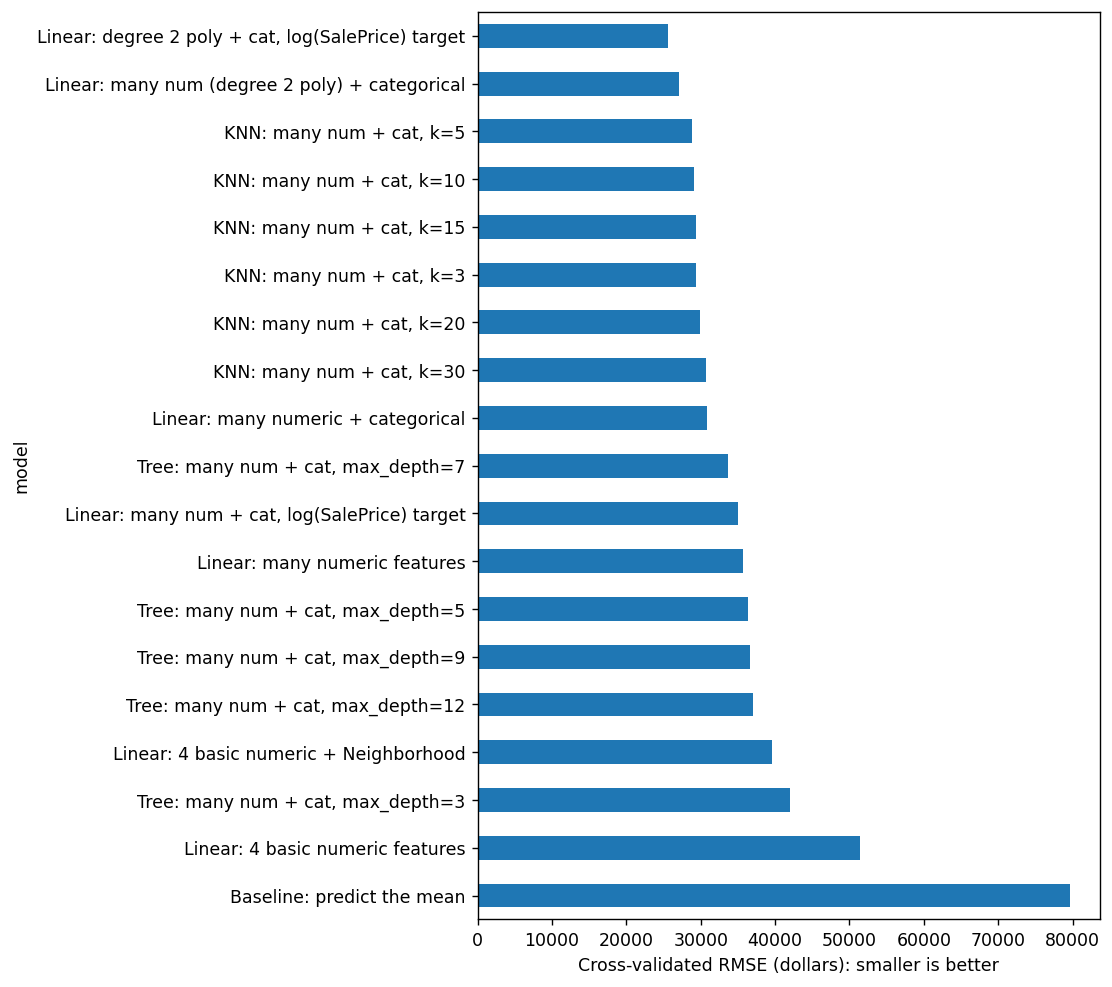

BEST MODEL: Linear: degree 2 poly + cat, log(SalePrice) target
Estimated test RMSE: $25,527   (+/- 3,396 across folds)


In [49]:
results_df = pd.DataFrame(results).sort_values("CV RMSE").reset_index(drop=True)
results_df.index = results_df.index + 1                       # rank 1 = best
pd.options.display.float_format = "{:,.0f}".format
display(results_df)
pd.reset_option("display.float_format")

# Bar chart (smaller is better)
ax = results_df.sort_values("CV RMSE", ascending=False).plot.barh(
        x="model", y="CV RMSE", legend=False, figsize=(9, 8), xerr=results_df.sort_values("CV RMSE", ascending=False)["std across folds"])
ax.set_xlabel("Cross-validated RMSE (dollars): smaller is better")
plt.tight_layout()
plt.show()

best = results_df.iloc[0]
print(f"BEST MODEL: {best['model']}")
print(f"Estimated test RMSE: ${best['CV RMSE']:,.0f}   (+/- {best['std across folds']:,.0f} across folds)")

### Step 5: Which model is best, and why?

I choose the model with the **smallest cross-validated RMSE** (rank 1 in the table above; the code prints its name and RMSE). I trust cross-validation, not training RMSE, because it estimates how the model will do on houses it has not seen, and every model was scored on the same 10 folds so the comparison is fair. Some things to keep in mind when you read the table:

- A difference smaller than the **"std across folds"** is within noise. If a simpler model is within about one fold standard deviation of the top model, the simpler model is a perfectly good choice.
- Compare every model to the **baseline** (always predicting the mean price): the baseline RMSE is about the standard deviation of SalePrice.
- Expect the models that use **quality and size information** (Overall Qual, Gr Liv Area, ...) plus **Neighborhood** to beat the 4-feature model by a wide margin, and a log-transformed target to help a linear model because of the fan shape in the price plot.
- Within KNN and trees, the best k and the best depth are in the middle: very small k and very deep trees overfit, and large k and shallow trees underfit.

**Final step:** once a model is chosen, **refit it on all of the data** (cross-validation was only for choosing and for estimating the test error).

In [50]:
# Refit the winning model on ALL of the data and keep it for predictions
best_model = fitted_later[best["model"]]
best_model.fit(X, y)

# Example: predict the price of the first 5 houses
pd.DataFrame({"actual": y.head(), "predicted": best_model.predict(X.head()).round(0)})

,actual,predicted
0,215000,211166.0
1,105000,122044.0
2,172000,163588.0
3,244000,299720.0
4,189900,172965.0
